In [15]:
import gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

In [9]:
import random
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [16]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_size=512):
        super(ActorCritic, self).__init__()
        # Shared layer
        self.fc = nn.Linear(state_dim, hidden_size)
        
        # Policy (actor) head
        self.policy = nn.Linear(hidden_size, action_dim)
        
        # Value (critic) head
        self.value = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = torch.tanh(self.fc(x))
        policy_logits = self.policy(x)
        value = self.value(x)
        return policy_logits, value

In [17]:
def compute_returns_and_advantages(rewards, values, dones, gamma, lam):
    advantages = []
    gae = 0
    values = values + [0]  # Add a dummy for bootstrap
    
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns


In [18]:
def ppo_update(model, optimizer, states, actions, log_probs_old, returns, advantages, clip_eps):
    states = torch.tensor(states, dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64)
    log_probs_old = torch.tensor(log_probs_old, dtype=torch.float32)
    returns = torch.tensor(returns, dtype=torch.float32)
    advantages = torch.tensor(advantages, dtype=torch.float32)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    policy_logits, values = model(states)
    dist = Categorical(logits=policy_logits)
    log_probs_new = dist.log_prob(actions)
    ratio = torch.exp(log_probs_new - log_probs_old)

    # Clipped surrogate objective
    clipped = torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * advantages
    actor_loss = -torch.min(ratio * advantages, clipped).mean()

    # Critic loss (MSE)
    critic_loss = nn.MSELoss()(values.squeeze(), returns)

    # Total loss
    # loss = actor_loss + 0.5 * critic_loss
    entropy = dist.entropy().mean()
    loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


In [19]:


# Train function returning rewards
def train_ppo(model, optimizer, env, max_env_steps, batch_size, gamma, lambda_, clip_eps):
    reward_per_episode = []
    env_steps = []
    step_counter = 0
    while step_counter < max_env_steps:
        states, actions, rewards, dones, log_probs, values = [], [], [], [], [], []
        state, _ = env.reset()
        ep_reward = 0

        while True:
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            logits, value = model(state_tensor)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            states.append(state)
            actions.append(action.item())
            rewards.append(reward)
            dones.append(done)
            log_probs.append(dist.log_prob(action).item())
            values.append(value.item())

            state = next_state
            ep_reward += reward
            step_counter +=1
            if done or step_counter >= max_env_steps:
                break

        advantages, returns = compute_returns_and_advantages(rewards, values, dones, gamma, lambda_)
        ppo_update(model, optimizer, states, actions, log_probs, returns, advantages, clip_eps)
        reward_per_episode.append(ep_reward)
        env_steps.append(step_counter)
        print(f"Step {step_counter}/{max_env_steps} | Reward: {ep_reward}")


    return reward_per_episode, env_steps


In [20]:

config = {
    'learning_rate': 1e-3,
    'batch_size': 3000,
    'gamma': 0.99,
    'lambda': 0.95,
    'clip_eps': 0.4
}


MAX_ENV_STEPS = 100000
REPEATS = 5
results = []

for rep in range(REPEATS):
    print(f"\n=== Run {rep+1}/{REPEATS} ===")
    seed = 42 + rep
    set_seed(seed)

    env = gym.make("CartPole-v1")
    env.reset(seed=seed)

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    model = ActorCritic(state_dim, action_dim)
    optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])

    episode_return, env_step = train_ppo(
        model=model,
        optimizer=optimizer,
        env=env,
        max_env_steps=MAX_ENV_STEPS,
        batch_size=config['batch_size'],
        gamma=config['gamma'],
        lambda_=config['lambda'],
        clip_eps=config['clip_eps']
    )

    results.append((episode_return, env_step))


=== Run 1/5 ===
Step 81/100000 | Reward: 81.0
Step 97/100000 | Reward: 16.0
Step 129/100000 | Reward: 32.0
Step 142/100000 | Reward: 13.0
Step 150/100000 | Reward: 8.0
Step 165/100000 | Reward: 15.0
Step 179/100000 | Reward: 14.0
Step 190/100000 | Reward: 11.0
Step 202/100000 | Reward: 12.0
Step 217/100000 | Reward: 15.0
Step 236/100000 | Reward: 19.0
Step 253/100000 | Reward: 17.0
Step 281/100000 | Reward: 28.0
Step 296/100000 | Reward: 15.0
Step 307/100000 | Reward: 11.0
Step 322/100000 | Reward: 15.0
Step 340/100000 | Reward: 18.0
Step 370/100000 | Reward: 30.0
Step 382/100000 | Reward: 12.0
Step 398/100000 | Reward: 16.0
Step 412/100000 | Reward: 14.0
Step 424/100000 | Reward: 12.0
Step 446/100000 | Reward: 22.0
Step 478/100000 | Reward: 32.0
Step 497/100000 | Reward: 19.0
Step 514/100000 | Reward: 17.0
Step 530/100000 | Reward: 16.0
Step 556/100000 | Reward: 26.0
Step 567/100000 | Reward: 11.0
Step 593/100000 | Reward: 26.0
Step 618/100000 | Reward: 25.0
Step 662/100000 | Reward:

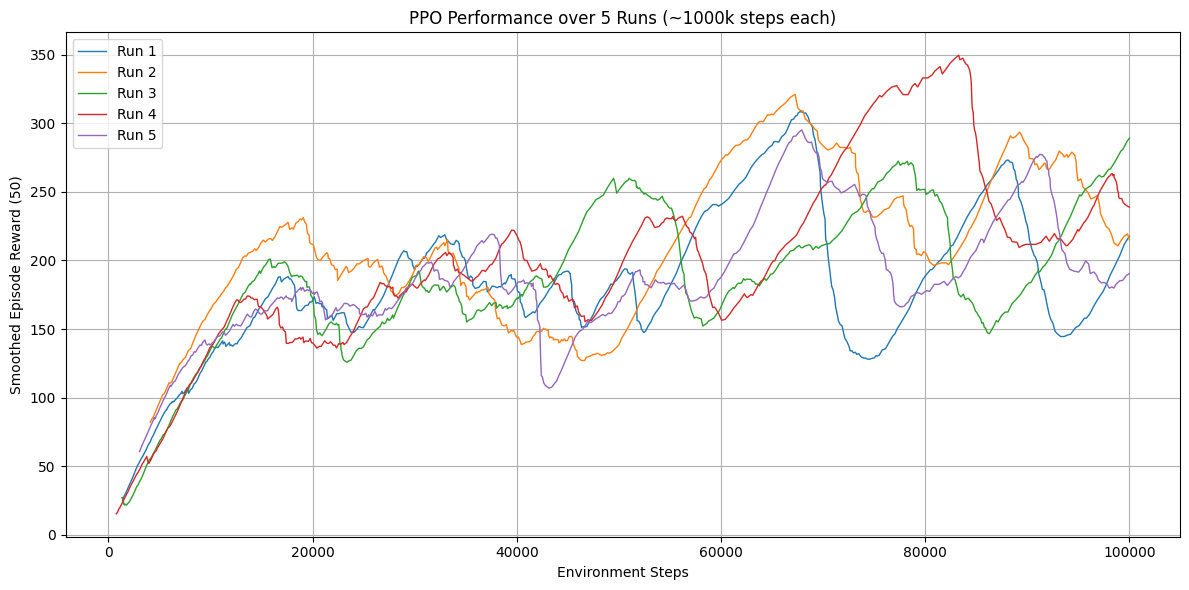

In [23]:
import matplotlib.pyplot as plt
window_size = 50
plt.figure(figsize=(12, 6))

for i, (episode_return, env_step) in enumerate(results):
    episode_return_smooth = np.convolve(episode_return, np.ones(window_size)/window_size, mode='valid')
    env_step_aligned = env_step[window_size - 1:]
    plt.plot(env_step_aligned, episode_return_smooth, label=f'Run {i+1}', linewidth=1)

plt.xlabel('Environment Steps')
plt.ylabel('Smoothed Episode Reward (50)')
plt.title('PPO Performance over 5 Runs (~1000k steps each)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
